In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

print(os.getcwd())
print(os.listdir())

/home/alexander16/aequo-finance/data
['ps_data.csv', '01_btc_analysis.ipynb', '.ipynb_checkpoints', '__pycache__', 'data_feed.py', 'astronomical_data.ipynb', 'data_analysis_structure.txt']


In [3]:
df = pd.read_csv("ps_data.csv", comment="#", usecols=["pl_name", "discoverymethod", "disc_year", "pl_orbper",
"pl_rade", "pl_bmasse", "pl_eqt", "rowupdate", "pl_pubdate", "default_flag"])
df.head(10)

,pl_name,default_flag,discoverymethod,disc_year,pl_orbper,pl_rade,pl_bmasse,pl_eqt,rowupdate,pl_pubdate
0,11 Com b,0,Radial Velocity,2007,NaN,NaN,5434.700000,NaN,2014-07-23,2011-08
1,11 Com b,1,Radial Velocity,2007,323.21000,NaN,4914.898486,NaN,2023-09-19,2023-12
2,11 Com b,0,Radial Velocity,2007,326.03000,NaN,6165.600000,NaN,2014-05-14,2008-01
3,11 UMi b,1,Radial Velocity,2009,516.21997,NaN,4684.814200,NaN,2018-09-04,2017-03
4,11 UMi b,0,Radial Velocity,2009,NaN,NaN,3432.400000,NaN,2018-04-25,2011-08
5,11 UMi b,0,Radial Velocity,2009,516.22000,NaN,3337.070000,NaN,2018-04-25,2009-10
6,14 And b,0,Radial Velocity,2008,185.84000,NaN,1525.500000,NaN,2014-05-14,2008-12
7,14 And b,1,Radial Velocity,2008,186.76000,NaN,1131.151301,NaN,2023-09-19,2023-12
8,14 And b,0,Radial Velocity,2008,NaN,NaN,1017.000000,NaN,2014-07-23,2011-08
9,14 Her b,0,Radial Velocity,2002,1796.40000,NaN,1506.450000,NaN,2018-04-25,2004-01


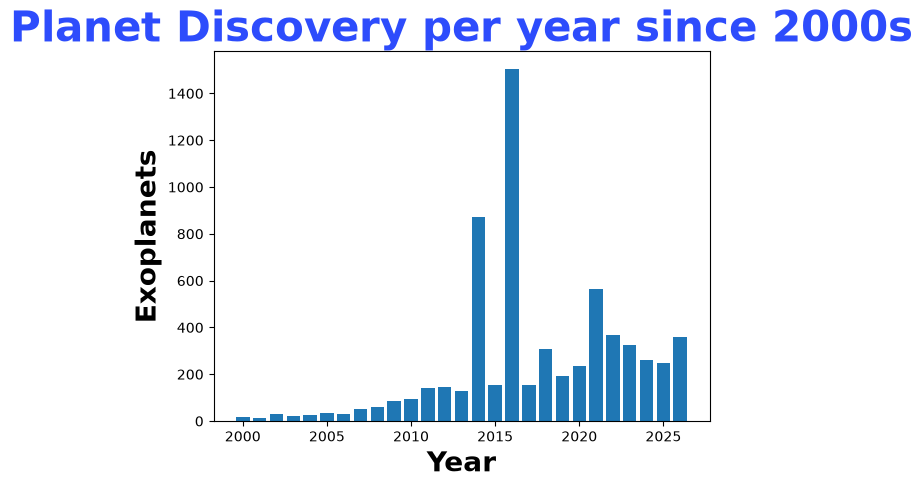

In [3]:
pl_filtered = df[(df["disc_year"] >= 2000) & (df["default_flag"] == 1)]
pl_disc_year = pl_filtered["disc_year"].value_counts().sort_index()

x = pl_disc_year.index
y = pl_disc_year.values

plt.title("Planet Discovery per year since 2000s", fontsize=30, fontweight="bold",
          color="#2d4cfc")

plt.xlabel("Year", fontsize= 20, fontweight="bold",
           color="black")

plt.ylabel("Exoplanets", fontsize= 20, fontweight="bold",
           color="black")

plt.Figure(figsize=(12,6))
plt.bar(x, y)
plt.show()

In [2]:
from sqlalchemy import create_engine

engine = create_engine(os.getenv("EXOPLANET_DB_URL"))

#For star_systems table
df_db = pd.read_csv("ps_data.csv", comment="#", 
                    usecols=["hostname", "default_flag", "sy_snum", "sy_pnum", "st_teff", "st_rad", "st_mass", "st_logg",
                             "sy_dist"])


df_stars = (
    df_db[(df_db['default_flag'] == 1) & df_db['hostname'].notna()]
    .drop_duplicates(subset='hostname')
    .drop(columns='default_flag')
)



In [5]:
#For exoplanets_data table
df_db = pd.read_csv("ps_data.csv", comment="#", 
                    usecols=["pl_name", "default_flag", "discoverymethod", "disc_year", "pl_orbper",
                              "pl_rade", "pl_bmasse", "pl_eqt", "rowupdate", "pl_pubdate", "hostname"])

df_exoplanets = (
    df_db[(df_db['default_flag'] == 1) & (df_db['pl_name'].notna())]
    .drop_duplicates(subset="pl_name")
    .copy()
)

df_exoplanets['rowupdate'] = pd.to_datetime(df_exoplanets['rowupdate']).dt.date



In [48]:
df_exoplanets.sample(5)

,pl_name,hostname,default_flag,discoverymethod,disc_year,pl_orbper,pl_rade,pl_bmasse,pl_eqt,rowupdate,pl_pubdate
37525,TOI-3362 b,TOI-3362,1,Transit,2021,18.095470,12.800656,1598.359059,NaN,2021-10-19,2021-10
1616,HAT-P-8 b,HAT-P-8,1,Transit,2008,3.076340,15.692600,406.822400,NaN,2018-04-25,2017-03
15381,Kepler-1589 b,Kepler-1589,1,Transit,2016,0.991665,1.090000,NaN,NaN,2016-05-06,2016-05
35623,MOA-2009-BLG-319L b,MOA-2009-BLG-319L,1,Microlensing,2010,NaN,NaN,67.300000,NaN,NaT,2021-02
5538,K2-293 b,K2-293,1,Transit,2019,13.122500,2.450000,NaN,750.0,2019-04-01,2019-05


<Axes: xlabel='discoverymethod'>

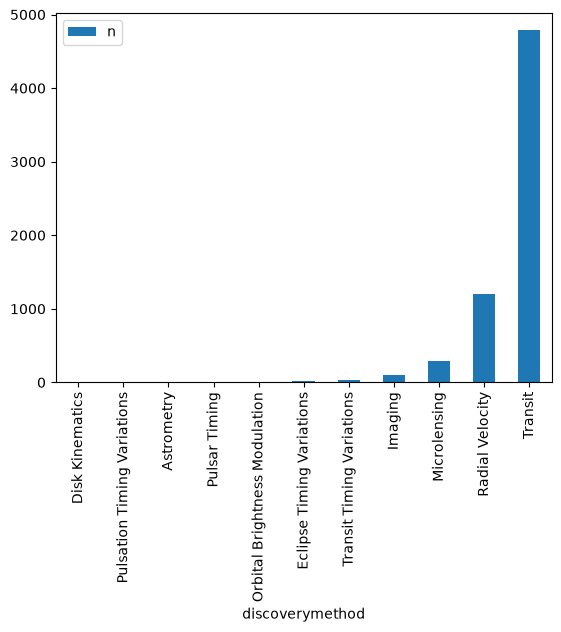

In [ ]:
df_sample1 = pd.read_sql("""
    SELECT discoverymethod, COUNT(*) AS n
    FROM exoplanets_data
    GROUP BY discoverymethod
    ORDER BY n 
    
    
""", engine)

df_sample1.plot.bar(x="discoverymethod", y="n")

<Axes: ylabel='Frequency'>

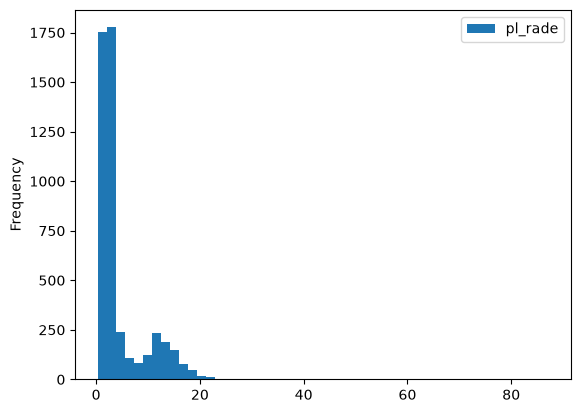

In [43]:
df_sample2 = pd.read_sql("""
    SELECT pl_rade FROM exoplanets_data WHERE pl_rade IS NOT NULL
""", engine)

df_sample2.plot.hist(bins=50)

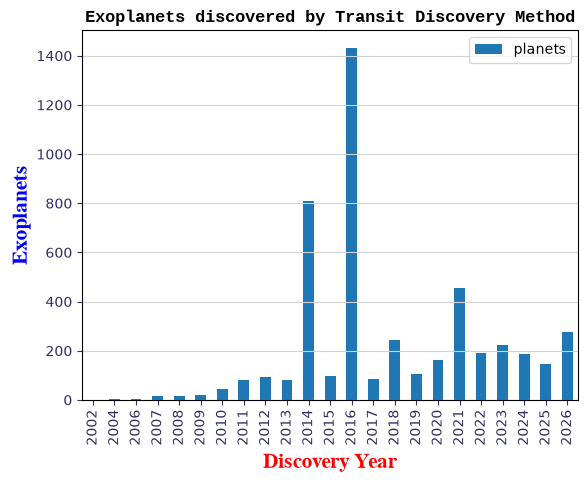

In [97]:
df_sample3 = pd.read_sql("""
    SELECT disc_year, COUNT(*) AS planets
    FROM exoplanets_data
    WHERE discoverymethod = 'Transit'
    GROUP BY disc_year
    ORDER BY disc_year ASC

""", engine)

df_sample3.plot.bar(x='disc_year', y='planets')
plt.title('Exoplanets discovered by Transit Discovery Method', family="Liberation Mono",
          fontweight="bold",
          color="black")

plt.xlabel("Discovery Year", fontsize= 15,
           family="FreeSerif",
           fontweight="bold",
           color="red")

plt.ylabel("Exoplanets", fontsize=15,
           family="FreeSerif",
           fontweight="bold",
           color="blue")

plt.tick_params(axis="both",
                colors="#2e2e63")

plt.grid(axis="y",
         color="lightgray")

In [65]:
import matplotlib.font_manager as fm 

fonts = sorted(set(fm.get_font_names()))

print(fonts)

['DejaVu Math TeX Gyre', 'DejaVu Sans', 'DejaVu Sans Condensed', 'DejaVu Sans Display', 'DejaVu Sans Light', 'DejaVu Sans Mono', 'DejaVu Serif', 'DejaVu Serif Condensed', 'DejaVu Serif Display', 'FontAwesome', 'FreeMono', 'FreeSans', 'FreeSerif', 'GLYPHICONS Halflings', 'Last Resort High-Efficiency', 'Liberation Mono', 'Liberation Sans', 'Liberation Sans Narrow', 'Liberation Serif', 'MathJax_AMS', 'MathJax_Caligraphic', 'MathJax_Fraktur', 'MathJax_Main', 'MathJax_Math', 'MathJax_SansSerif', 'MathJax_Script', 'MathJax_Size1', 'MathJax_Size2', 'MathJax_Size3', 'MathJax_Size4', 'MathJax_Typewriter', 'MathJax_Vector', 'MathJax_Vector-Bold', 'MathJax_WinChrome', 'MathJax_WinIE6', 'STIXGeneral', 'STIXNonUnicode', 'STIXSizeFiveSym', 'STIXSizeFourSym', 'STIXSizeOneSym', 'STIXSizeThreeSym', 'STIXSizeTwoSym', 'Ubuntu', 'Ubuntu Mono', 'Ubuntu Sans', 'Ubuntu Sans Mono', 'cmb10', 'cmex10', 'cmmi10', 'cmr10', 'cmss10', 'cmsy10', 'cmti10', 'cmtt10', 'dsrom10', 'esint10', 'eufm10', 'msam10', 'msbm10',